## ЛР3. Задача классификации

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

## Этапы

<font color='DarkOrange'>**Задание 1 [баллов: 2]:**</font>

Выберите датасет и задачу для него (классификация) - с Kaggle или UCI Machine Learning Repository (https://archive.ics.uci.edu/datasets).
Важно: используйте более новые датасеты, кол-во объектов не менее 100.
Лучше воспользоваться датасетом из предыдущих ЛР.

Выберите (или сгенерите сами) признак, который будет целевым для бинарной классификации.

Используйте LogisticRegression из sklearn. Задайте несколько параметров метода самостоятельно, поясните их назначение и причину выбора конкретных значений.
Используйте несколько метрик, чтоб оценить результаты бинарной классификации (метрики, доступные в sklearn).

### 1. Данные и постановка задачи
Используем предоставленный `dataset.csv`: характеристики и цены смартфонов, 407 исходных наблюдений. По структуре он соответствует [Mobile Phone Price на Kaggle](https://www.kaggle.com/datasets/rkiattisak/mobile-phone-price). Дата сбора и версия локального файла не указаны; не считаем эти цены актуальными на сегодня.

Бинарная цель: **дорогой смартфон**, `Price ≥ 500 $`. Порог фиксирован заранее и имеет понятный смысл. Цена используется только для формирования цели, а название модели — только для группировки при разбиении. Признаки: бренд, память, RAM, диагональ, основная камера, число камер и аккумулятор. Из строк извлекаем числовые значения; `3D` и `ToF` не считаем мегапикселями. Формат `7.6 (unfolded)` означает диагональ раскрытого экрана.

После нормализации удаляем полные дубликаты. Схожие варианты одного телефона остаются в одной группе `Brand + Model`: тест имитирует прогноз для **ранее не встречавшихся моделей**. Масштабирование, заполнение пропусков и кодирование обучаются внутри Pipeline только на обучающей части.

In [1]:
import re
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, OneClassSVM
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay)
import sklearn

SEED = 42
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': .2})
print('Python:', sys.version.split()[0], '| sklearn:', sklearn.__version__)
raw = pd.read_csv('dataset.csv', encoding='utf-8-sig')
raw.columns = raw.columns.str.strip()
df = raw.copy()
for col in ['Brand', 'Model']:
    df[col] = df[col].str.strip()
def first_number(value):
    found = re.search(r'\d+(?:\.\d+)?', str(value).replace(',', ''))
    return float(found.group()) if found else np.nan
for source, target in [('Storage', 'storage_gb'), ('RAM', 'ram_gb'),
                       ('Screen Size (inches)', 'screen_inches'),
                       ('Battery Capacity (mAh)', 'battery_mah'), ('Price ($)', 'price_usd')]:
    df[target] = df[source].map(first_number)
def camera_values(value):
    return [first_number(part) for part in str(value).split('+')
            if not re.search(r'3D|ToF', part, flags=re.I)]
df['camera_main_mp'] = df['Camera (MP)'].map(lambda x: camera_values(x)[0])
df['camera_count'] = df['Camera (MP)'].map(lambda x: len(str(x).split('+')))
num_cols = ['storage_gb', 'ram_gb', 'screen_inches', 'camera_main_mp', 'camera_count', 'battery_mah']
normalized_cols = ['Brand', 'Model'] + num_cols + ['price_usd']
df = df[normalized_cols].drop_duplicates().reset_index(drop=True)
assert df.price_usd.notna().all() and (df.price_usd > 0).all()
assert len(df) >= 100
print(f'Исходных строк: {len(raw)}; после нормализации и удаления повторов: {len(df)}')
display(df.head(), df[num_cols + ['price_usd']].describe().round(2))
print('Пропуски:', df.isna().sum().to_dict())
X = df[['Brand'] + num_cols]
y = (df.price_usd >= 500).astype(int)
y_multi = pd.Series(np.select([df.price_usd < 250, df.price_usd < 500], [0, 1], default=2), index=df.index)
class_names = ['Бюджет (<250)', 'Средний (250–499)', 'Дорогой (≥500)']
groups = df.Brand.str.casefold() + '|' + df.Model.str.casefold()
# Общий holdout для бинарной и многоклассовой задач, стратификация по трём сегментам.
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_cv.split(X, y_multi, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
ym_train, ym_test = y_multi.iloc[train_idx], y_multi.iloc[test_idx]
g_train = groups.iloc[train_idx]
assert set(g_train).isdisjoint(set(groups.iloc[test_idx]))
display(pd.DataFrame({'Все': y_multi.value_counts(), 'Train': ym_train.value_counts(),
                      'Test': ym_test.value_counts()}).sort_index().rename(index=dict(enumerate(class_names))))
print('Бинарные классы (train):', y_train.value_counts().sort_index().to_dict())
print('Объектов train/test:', len(train_idx), len(test_idx))

def preprocessing():
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    return ColumnTransformer([('numeric', numeric, num_cols),
                              ('brand', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Brand'])])
def classifier_pipeline(model):
    return Pipeline([('preprocess', preprocessing()), ('model', model)])
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)

Python: 3.14.8 | sklearn: 1.9.1
Исходных строк: 407; после нормализации и удаления повторов: 357


,Brand,Model,storage_gb,ram_gb,screen_inches,camera_main_mp,camera_count,battery_mah,price_usd
0,Apple,iPhone 13 Pro,128.0,6.0,6.10,12.0,3,3095.0,999.0
1,Samsung,Galaxy S21 Ultra,256.0,12.0,6.80,108.0,4,5000.0,1199.0
2,OnePlus,9 Pro,128.0,8.0,6.70,48.0,4,4500.0,899.0
3,Xiaomi,Redmi Note 10 Pro,128.0,6.0,6.67,64.0,4,5020.0,279.0
4,Google,Pixel 6,128.0,8.0,6.40,50.0,2,4614.0,799.0


,storage_gb,ram_gb,screen_inches,camera_main_mp,camera_count,battery_mah,price_usd
count,357.00,357.00,357.00,357.00,357.00,357.00,357.00
mean,124.68,5.89,6.48,43.44,3.14,4694.51,409.79
std,67.65,2.49,0.30,24.74,0.76,781.90,307.69
min,32.00,2.00,4.50,8.00,1.00,1821.00,99.00
25%,64.00,4.00,6.44,13.00,3.00,4300.00,199.00
50%,128.00,6.00,6.50,48.00,3.00,5000.00,299.00
75%,128.00,8.00,6.60,64.00,4.00,5000.00,499.00
max,512.00,16.00,7.60,108.00,4.00,7000.00,1999.00


Пропуски: {'Brand': 0, 'Model': 0, 'storage_gb': 0, 'ram_gb': 0, 'screen_inches': 0, 'camera_main_mp': 0, 'camera_count': 0, 'battery_mah': 0, 'price_usd': 0}


,Все,Train,Test
Бюджет (<250),146,117,29
Средний (250–499),128,102,26
Дорогой (≥500),83,66,17


Бинарные классы (train): {0: 219, 1: 66}
Объектов train/test: 285 72


### LogisticRegression: параметры и оценка
`C=1` задаёт обратную силу L2-регуляризации: умеренно ограничивает коэффициенты. `solver='lbfgs'` подходит для небольшой выборки и далее для многоклассовой модели. `max_iter=2000` даёт запас итераций после масштабирования. `class_weight='balanced'` повышает вклад редкого класса: вес равен $n/(K n_k)$. `random_state=42` фиксирует воспроизводимость там, где используется случайность (сам lbfgs детерминирован).

Accuracy показывает долю верных ответов, balanced accuracy — среднее recall двух классов, precision — долю дорогих среди предсказанных дорогих, recall — долю найденных дорогих, F1 — их гармоническое среднее. ROC AUC измеряет качество ранжирования, AP суммирует precision с весами приростов recall и полезна при дисбалансе. Предсказания LR используют порог 0.5; AUC и AP рассчитываются по непрерывным оценкам.

,accuracy,balanced_accuracy,precision,recall,F1,ROC AUC,AP
LogisticRegression,0.9444,0.923,0.8824,0.8824,0.8824,0.9342,0.9146


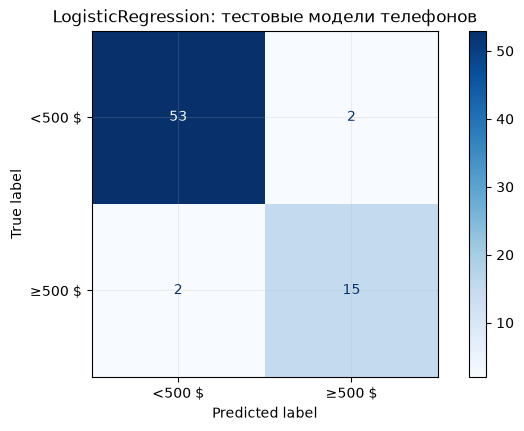

,Коэффициент
brand__Brand_Apple,2.387525
brand__Brand_Vivo,-2.147667
numeric__ram_gb,1.854877
brand__Brand_Asus,1.696334
numeric__battery_mah,-1.460968
brand__Brand_Realme,-1.433330
numeric__storage_gb,1.327892
numeric__screen_inches,1.045111
brand__Brand_Oppo,-0.798414
numeric__camera_count,-0.783944


**Вывод.** На отложенных моделях LR: accuracy=0.944, recall дорогих=0.882, precision=0.882, ROC AUC=0.934. Коэффициенты описывают связь с целью при фиксированных остальных признаках, но не доказывают причинность. Ограничения: небольшая выборка, фиксированный ценовой порог и отсутствие даты цены.

In [2]:
lr = classifier_pipeline(LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000,
                                                    class_weight='balanced', random_state=SEED))
lr.fit(X_train, y_train)
def evaluate_binary(model):
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    return {'accuracy': accuracy_score(y_test, pred),
            'balanced_accuracy': balanced_accuracy_score(y_test, pred),
            'precision': precision_score(y_test, pred, zero_division=0),
            'recall': recall_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0),
            'ROC AUC': roc_auc_score(y_test, score),
            'AP': average_precision_score(y_test, score)}
lr_metrics = evaluate_binary(lr)
display(pd.DataFrame([lr_metrics], index=['LogisticRegression']).round(4))
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test, display_labels=['<500 $', '≥500 $'], cmap='Blues')
plt.title('LogisticRegression: тестовые модели телефонов'); plt.show()
coef_names = lr.named_steps['preprocess'].get_feature_names_out()
display(pd.Series(lr.named_steps['model'].coef_[0], index=coef_names)
        .sort_values(key=abs, ascending=False).head(10).to_frame('Коэффициент'))
display(Markdown(f"**Вывод.** На отложенных моделях LR: accuracy={lr_metrics['accuracy']:.3f}, "
                 f"recall дорогих={lr_metrics['recall']:.3f}, precision={lr_metrics['precision']:.3f}, "
                 f"ROC AUC={lr_metrics['ROC AUC']:.3f}. Коэффициенты описывают связь с целью при "
                 "фиксированных остальных признаках, но не доказывают причинность. Ограничения: небольшая "
                 "выборка, фиксированный ценовой порог и отсутствие даты цены."))

<font color='DarkOrange'>**Задание 2 [баллов: 2]:**</font>

Выполните бинарную классификацию аналогично тпредыдущему пункту с использованием SVM (SVC из sklearn, используйте kernel=‘linear’, сами подберите параметр регуляризации С и ответьте на вопрос, может ли/как может SVM учесть несбалансированность классов)


### 2. Линейный SVM
SVM ищет разделяющую гиперплоскость с максимальным зазором; ошибки контролирует `C`. Малое `C` сильнее регуляризует и допускает больше нарушений зазора, большое — сильнее штрафует ошибки обучения. Подбираем `C ∈ {0.01, 0.1, 1, 10, 100}` и веса классов **на train** с групповой кросс-валидацией по F1 положительного класса. Тест не участвует в подборе.

SVM учитывает дисбаланс через `class_weight='balanced'` или заданный словарь весов, фактически заменяя $C$ на $C_k=Cw_k$. Можно также передать `sample_weight` отдельным наблюдениям. Сравниваем взвешенный и невзвешенный варианты; веса могут повышать recall ценой precision. Источник: [руководство sklearn по SVM](https://scikit-learn.org/stable/modules/svm.html#unbalanced-problems).

,param_model__C,param_model__class_weight,mean_test_score,std_test_score
4,1.00,NaN,0.8989,0.0348
5,1.00,balanced,0.8467,0.0548
6,10.00,NaN,0.8329,0.0718
8,100.00,NaN,0.8186,0.0625
3,0.10,balanced,0.8025,0.0506
7,10.00,balanced,0.7908,0.0472
2,0.10,NaN,0.7871,0.0338
9,100.00,balanced,0.7606,0.0680
1,0.01,balanced,0.7567,0.0755
0,0.01,NaN,0.5569,0.1003


Лучшие параметры: {'model__C': 1, 'model__class_weight': None}


,accuracy,balanced_accuracy,precision,recall,F1,ROC AUC,AP
LogisticRegression,0.9444,0.9230,0.8824,0.8824,0.8824,0.9342,0.9146
Linear SVC,0.9167,0.8235,1.0000,0.6471,0.7857,0.9299,0.9173


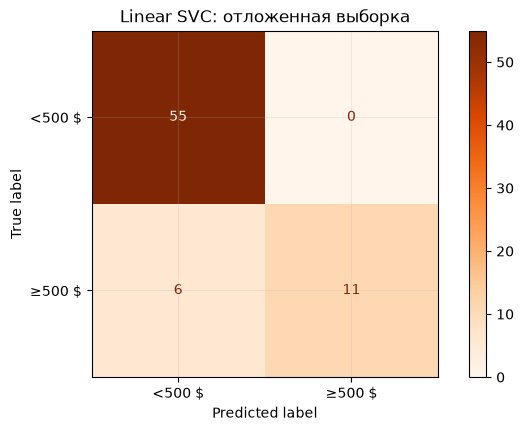

**Вывод.** По F1 на данном тесте лучший результат у LogisticRegression. Для SVC выбран C=1, class_weight=None; CV F1=0.899, test F1=0.786. Различие CV и теста связано с составом новых моделей телефонов. Один holdout не позволяет утверждать статистически значимое превосходство. decision_function SVM — оценка отступа, а не вероятность.

In [3]:
svm_search = GridSearchCV(classifier_pipeline(SVC(kernel='linear')),
    {'model__C': [.01, .1, 1, 10, 100], 'model__class_weight': [None, 'balanced']},
    scoring='f1', cv=cv, n_jobs=1, refit=True)
svm_search.fit(X_train, y_train, groups=g_train)
cv_results = pd.DataFrame(svm_search.cv_results_)
display(cv_results[['param_model__C', 'param_model__class_weight', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).round(4))
print('Лучшие параметры:', svm_search.best_params_)
svm = svm_search.best_estimator_
svm_metrics = evaluate_binary(svm)
binary_results = pd.DataFrame([lr_metrics, svm_metrics], index=['LogisticRegression', 'Linear SVC'])
display(binary_results.round(4))
ConfusionMatrixDisplay.from_estimator(svm, X_test, y_test, display_labels=['<500 $', '≥500 $'], cmap='Oranges')
plt.title('Linear SVC: отложенная выборка'); plt.show()
winner = binary_results['F1'].idxmax()
display(Markdown(f"**Вывод.** По F1 на данном тесте лучший результат у {winner}. "
    f"Для SVC выбран C={svm_search.best_params_['model__C']}, "
    f"class_weight={svm_search.best_params_['model__class_weight']}; "
    f"CV F1={svm_search.best_score_:.3f}, test F1={svm_metrics['F1']:.3f}. "
    "Различие CV и теста связано с составом новых моделей телефонов. Один holdout не позволяет "
    "утверждать статистически значимое превосходство. decision_function SVM — оценка отступа, а не вероятность."))

<font color='DarkOrange'>**Задание 3 [баллов: 6]:**</font>

1. Многоклассовая классификация. Дайте определения для подходов: микро, макро, взвешенный, пообъктный. Выполните расчёты вручную для слайда 43 (на примере любых 3 промежуточных AUC ROC, поясните, как из промежуточных характеристик получаются 4 финальных). В рамках детализации ОЦИФРУЙТЕ ROC: в Excel, отрисуйте линиями в Word или отрисуйте отдельными отрезками Python-кодом (не используйте готовые функции для ROC).
[баллов: 2]

2. Для одного из кейсов (одного класса) введите три порога бинаризации так, чтоб получились различные accuracy, recall, precision. Вычислите эти метрики вручную и сопроводите визуализацией расчёта для recall и precision (см пример из лекции с окружностями разных цветов и радиусов). По трём парам (precision, recall) постройте эскиз PR-кривой. [баллов: 2]

3. Сделайте выводы по результатам расчётом AUC ROC для многоклассовой классификации (какой вариант лучше, почему, объясните падение AUC ROC при переходе к многоклассовым). [баллов: 1]

4. В каких кейсах/доменах следует применять те или иные варианты? Запишите выводы. [баллов: 1]

### 3.1. Четыре способа усреднения и пример со слайда 43
На слайде 43 «Лекция 4 Ошибки и Ф качества.pdf» дана **многометочная** задача: у объектов 0 и 1 по две единицы. Поэтому оценки не обязаны суммироваться в 1. Переписываем обе матрицы без изменения.

- **Macro**: считаем AUC отдельно для каждого столбца (класса), затем среднее с одинаковыми весами: $\frac1K\sum_k A_k$.
- **Weighted**: среднее AUC классов с весами $n_k/\sum_j n_j$, где $n_k$ — число положительных меток класса. На слайде $P_k=n_k/n=(0.5,0.75,0.25)$; их сумма 1.5, поэтому требуется нормировка.
- **Micro**: разворачиваем обе матрицы в векторы длины $nK$ и строим одну ROC. Нельзя получить micro только из трёх AUC столбцов: нужны исходные оценки.
- **Пообъектный (samples)**: строим ROC по классам внутри каждой строки и усредняем AUC объектов. Нужны и положительные, и отрицательные метки внутри строки; при всех нулях/единицах AUC строки не определён.

Вручную используем ранжирование всех пар «положительный–отрицательный»: $AUC=(N_{>}+0.5N_{=})/(n_+ n_-)$, а для ROC перебираем уникальные пороги, подсчитываем TP/FP и соединяем точки отдельными отрезками. Площадь — сумма трапеций $\sum_i (FPR_{i+1}-FPR_i)(TPR_i+TPR_{i+1})/2$. Готовые функции ROC не используются.

,class 1,class 2,class 3
0,1,1,0
1,0,1,1
2,0,1,0
3,1,0,0


,class 1,class 2,class 3
0,0.7,0.6,0.5
1,0.3,0.4,0.6
2,0.5,0.9,0.2
3,0.4,0.5,0.1


Класс 1: (3 + 0.5×0) / 4 = 0.750000


,threshold,TP,FP,FN,TN,FPR,TPR,area_to_next
0,inf,0,0,2,2,0.0,0.0,0.00
1,0.7,1,0,1,2,0.0,0.5,0.25
2,0.5,1,1,1,1,0.5,0.5,0.00
3,0.4,2,1,0,1,0.5,1.0,0.50
4,0.3,2,2,0,0,1.0,1.0,NaN


Класс 2: (2 + 0.5×0) / 3 = 0.666667


,threshold,TP,FP,FN,TN,FPR,TPR,area_to_next
0,inf,0,0,3,1,0.0,0.0000,0.0000
1,0.9,1,0,2,1,0.0,0.3333,0.0000
2,0.6,2,0,1,1,0.0,0.6667,0.6667
3,0.5,2,1,1,0,1.0,0.6667,0.0000
4,0.4,3,1,0,0,1.0,1.0000,NaN


Класс 3: (3 + 0.5×0) / 3 = 1.000000


,threshold,TP,FP,FN,TN,FPR,TPR,area_to_next
0,inf,0,0,1,3,0.0000,0.0,0.0000
1,0.6,1,0,0,3,0.0000,1.0,0.3333
2,0.5,1,1,0,2,0.3333,1.0,0.3333
3,0.2,1,2,0,1,0.6667,1.0,0.3333
4,0.1,1,3,0,0,1.0000,1.0,NaN


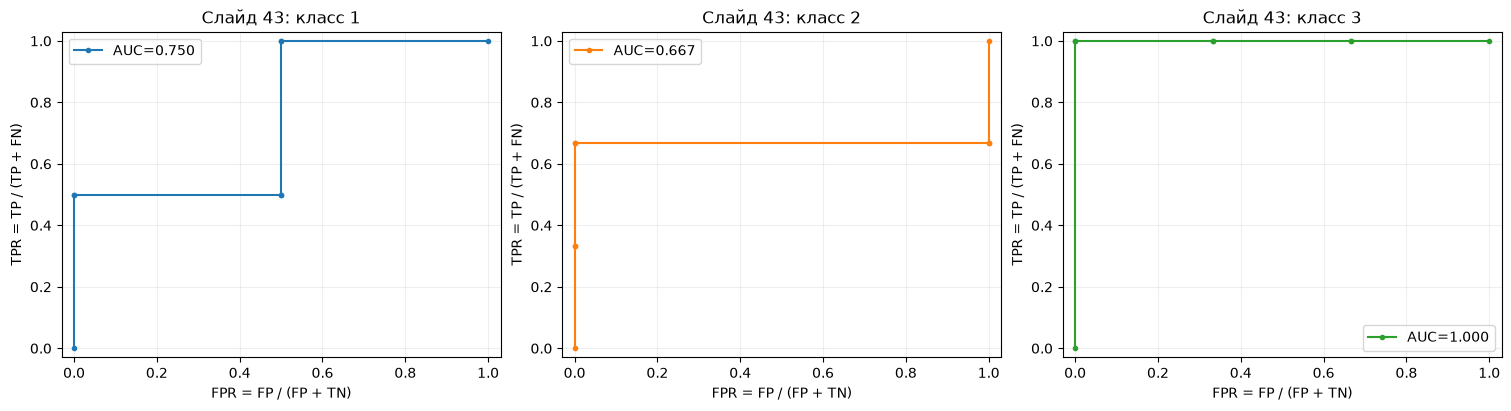

Macro = (3/4 + 2/3 + 1)/3 = 0.8055555555555555
Weighted = (2×3/4 + 3×2/3 + 1×1)/6 = 0.75
Micro: победы, совпадения, пары, AUC = (30, 0, 36, 0.8333333333333334)
Samples: (1 + 1 + 1 + 0.5)/4 = 0.875


,wins,ties,pairs,AUC
x1,2,0,2,1.0
x2,2,0,2,1.0
x3,2,0,2,1.0
x4,1,0,2,0.5


,threshold,TP,FP,FN,TN,FPR,TPR,area_to_next
0,inf,0,0,6,6,0.0000,0.0000,0.0000
1,0.9,1,0,5,6,0.0000,0.1667,0.0000
2,0.7,2,0,4,6,0.0000,0.3333,0.0000
3,0.6,4,0,2,6,0.0000,0.6667,0.3333
4,0.5,4,3,2,3,0.5000,0.6667,0.0000
5,0.4,6,3,0,3,0.5000,1.0000,0.1667
6,0.3,6,4,0,2,0.6667,1.0000,0.1667
7,0.2,6,5,0,1,0.8333,1.0000,0.1667
8,0.1,6,6,0,0,1.0000,1.0000,NaN


,macro,weighted,micro,samples
Ручной расчёт,0.805556,0.75,0.833333,0.875


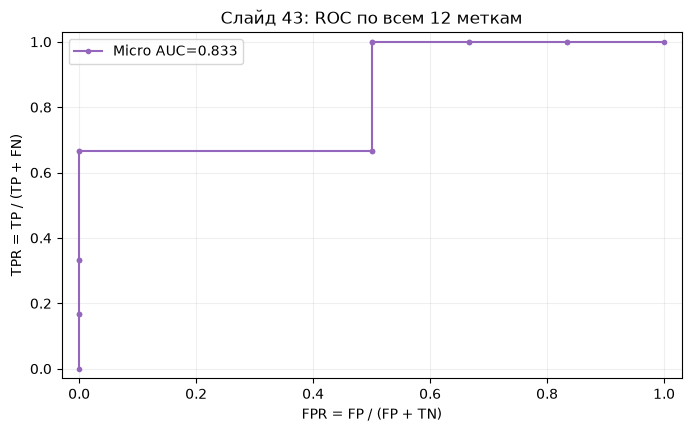

In [4]:
lecture_y = np.array([[1, 1, 0], [0, 1, 1], [0, 1, 0], [1, 0, 0]])
lecture_score = np.array([[.7, .6, .5], [.3, .4, .6], [.5, .9, .2], [.4, .5, .1]])
display(pd.DataFrame(lecture_y, columns=['class 1','class 2','class 3']),
        pd.DataFrame(lecture_score, columns=['class 1','class 2','class 3']))

def manual_roc(truth, scores):
    truth, scores = np.asarray(truth), np.asarray(scores)
    positives, negatives = int(truth.sum()), int((truth == 0).sum())
    if not positives or not negatives:
        raise ValueError('Для ROC необходимы оба класса')
    rows = []
    for threshold in np.r_[np.inf, np.sort(np.unique(scores))[::-1]]:
        pred = scores >= threshold
        tp = int(((truth == 1) & pred).sum())
        fp = int(((truth == 0) & pred).sum())
        rows.append([threshold, tp, fp, positives - tp, negatives - fp, fp/negatives, tp/positives])
    table = pd.DataFrame(rows, columns=['threshold','TP','FP','FN','TN','FPR','TPR'])
    table['area_to_next'] = (table.FPR.shift(-1) - table.FPR) * (table.TPR.shift(-1) + table.TPR) / 2
    return table, float(table.area_to_next.sum())

def pair_auc(truth, scores):
    truth, scores = np.asarray(truth), np.asarray(scores)
    positive, negative = scores[truth == 1], scores[truth == 0]
    differences = positive[:, None] - negative[None, :]
    wins, ties, total = int((differences > 0).sum()), int((differences == 0).sum()), differences.size
    return wins, ties, total, (wins + .5 * ties) / total

def draw_segments(ax, table, label, color):
    for i in range(len(table)-1):
        ax.plot(table.FPR.iloc[i:i+2], table.TPR.iloc[i:i+2], color=color,
                marker='o', markersize=3, label=label if i == 0 else None)
    ax.set(xlabel='FPR = FP / (FP + TN)', ylabel='TPR = TP / (TP + FN)', xlim=(-.03,1.03), ylim=(-.03,1.03))

fig, axes = plt.subplots(1,3,figsize=(15,4), constrained_layout=True)
lecture_aucs = []
for k, color in enumerate(['tab:blue','tab:orange','tab:green']):
    table, area = manual_roc(lecture_y[:,k], lecture_score[:,k])
    wins,ties,total,pair_area = pair_auc(lecture_y[:,k], lecture_score[:,k])
    assert np.isclose(area, pair_area)
    lecture_aucs.append(area)
    print(f'Класс {k+1}: ({wins} + 0.5×{ties}) / {total} = {area:.6f}')
    display(table.round(4))
    draw_segments(axes[k], table, f'AUC={area:.3f}', color)
    axes[k].set_title(f'Слайд 43: класс {k+1}'); axes[k].legend()
plt.show()
support = lecture_y.sum(axis=0)
macro = np.mean(lecture_aucs)
weighted = np.dot(support, lecture_aucs) / support.sum()
micro_table, micro = manual_roc(lecture_y.ravel(), lecture_score.ravel())
sample_details = [pair_auc(row, score) for row,score in zip(lecture_y, lecture_score)]
samples = np.mean([row[-1] for row in sample_details])
print('Macro = (3/4 + 2/3 + 1)/3 =', macro)
print('Weighted = (2×3/4 + 3×2/3 + 1×1)/6 =', weighted)
print('Micro: победы, совпадения, пары, AUC =', pair_auc(lecture_y.ravel(), lecture_score.ravel()))
print('Samples: (1 + 1 + 1 + 0.5)/4 =', samples)
display(pd.DataFrame(sample_details, columns=['wins','ties','pairs','AUC'], index=['x1','x2','x3','x4']))
display(micro_table.round(4))
lecture_final = {'macro': macro, 'weighted': weighted, 'micro': micro, 'samples': samples}
for average, area in lecture_final.items():
    assert np.isclose(area, roc_auc_score(lecture_y, lecture_score, average=average))
display(pd.DataFrame([lecture_final], index=['Ручной расчёт']).round(6))
fig, ax = plt.subplots()
draw_segments(ax, micro_table, f'Micro AUC={micro:.3f}', 'tab:purple')
ax.set_title('Слайд 43: ROC по всем 12 меткам'); ax.legend(); plt.show()

**Ручной результат.** Для класса 1 положительные оценки 0.7 и 0.4, отрицательные 0.3 и 0.5: три победы из четырёх → 0.75. Для класса 2 положительные 0.6, 0.4, 0.9 против отрицательной 0.5: две победы из трёх → 2/3. Для класса 3 единственная положительная 0.6 больше всех трёх отрицательных → 1.

Итого macro = 29/36 ≈ **0.805556**, weighted = **0.75**, micro = 30/36 ≈ **0.833333** (30 строгих побед, равенств нет), samples = **0.875**. Округлённые результаты совпадают со слайдом. Для четвёртого объекта положительный класс 1 с оценкой 0.4 выигрывает у 0.1, но проигрывает 0.5: AUC = 1/2.

### 3.2. Три порога, ручные метрики и PR
Для класса 2 со слайда выбираем пороги **0.4, 0.55, 0.8**; положительный ответ при `score ≥ threshold`. TP — найденные положительные, FP — ошибочные положительные, FN — пропущенные положительные, TN — верные отрицательные.

$accuracy=(TP+TN)/n$, $recall=TP/(TP+FN)$, $precision=TP/(TP+FP)$.

При 0.4: TP=3, FP=1, FN=0, TN=0 → accuracy=3/4, recall=1, precision=3/4.
При 0.55: TP=2, FP=0, FN=1, TN=1 → accuracy=3/4, recall=2/3, precision=1.
При 0.8: TP=1, FP=0, FN=2, TN=1 → accuracy=1/2, recall=1/3, precision=1.

Получаем три разных набора метрик; каждая метрика изменяется, но значения accuracy и precision частично повторяются. На четырёх объектах класса 2 **невозможно** получить одновременно по три попарно различных значения всех трёх метрик: при хотя бы одном предсказанном положительном возможны наборы (accuracy, recall, precision): (0.5, 1/3, 1), (0.75, 2/3, 1), (0.5, 2/3, 2/3), (0.75, 1, 0.75). Чтобы recall были разными, нужны первый, последний и один из двух средних наборов; в каждом случае accuracy повторяется. При отсутствии предсказанных положительных precision математически не определён. Ниже дополнительно найдём три порога для реального класса смартфонов, где все три метрики попарно различны.

На диаграммах кругов цвет обозначает истинный класс (синий — положительный, оранжевый — отрицательный), большой радиус — предсказанный положительный, малый — отрицательный. Recall считает большие синие среди всех синих; precision — синие среди всех больших.

,threshold,TP,FP,FN,TN,accuracy,recall,precision
0,0.40,3,1,0,0,0.75,1.0000,0.75
1,0.55,2,0,1,1,0.75,0.6667,1.00
2,0.80,1,0,2,1,0.50,0.3333,1.00


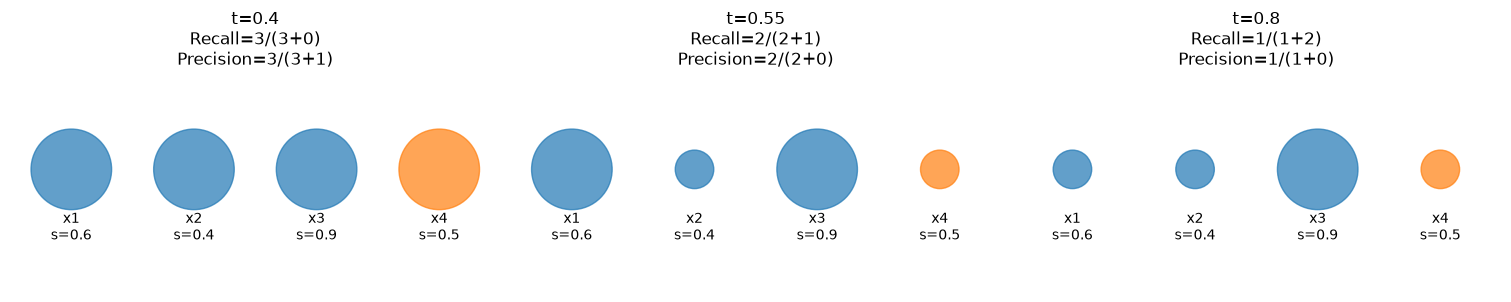

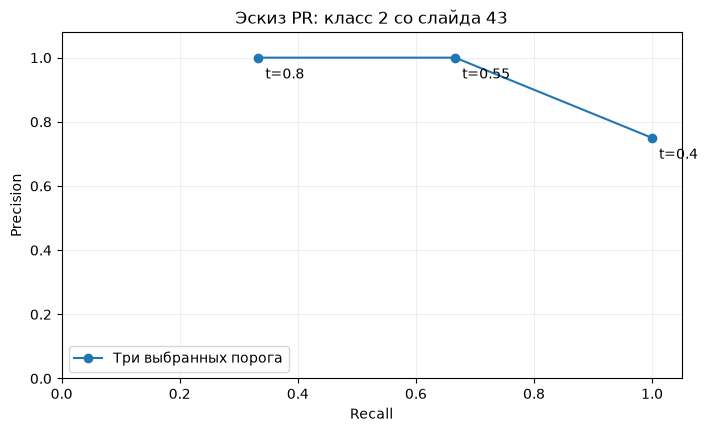

In [5]:
def threshold_metrics(truth, scores, thresholds):
    truth = np.asarray(truth)
    rows = []
    for t in thresholds:
        pred = np.asarray(scores) >= t
        tp = int(((truth==1)&pred).sum()); fp = int(((truth==0)&pred).sum())
        fn = int(((truth==1)&~pred).sum()); tn = int(((truth==0)&~pred).sum())
        rows.append({'threshold':t,'TP':tp,'FP':fp,'FN':fn,'TN':tn,
                     'accuracy':(tp+tn)/len(truth),'recall':tp/(tp+fn),
                     'precision':tp/(tp+fp) if tp+fp else 0.0})
    return pd.DataFrame(rows)
thresholds = [.4,.55,.8]
lecture_thresholds = threshold_metrics(lecture_y[:,1],lecture_score[:,1],thresholds)
display(lecture_thresholds.round(4))
fig, axes = plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for ax,t,row in zip(axes,thresholds,lecture_thresholds.to_dict('records')):
    for i,(truth,score) in enumerate(zip(lecture_y[:,1],lecture_score[:,1])):
        predicted = score >= t
        ax.add_patch(Circle((i*1.4,0), .46 if predicted else .22,
                           color='tab:blue' if truth else 'tab:orange', alpha=.7))
        ax.text(i*1.4,-.8,f'x{i+1}\ns={score}',ha='center')
    ax.set(xlim=(-.7,4.9),ylim=(-1.4,1.1),aspect='equal')
    ax.axis('off')
    ax.set_title(f"t={t}\nRecall={row['TP']}/({row['TP']}+{row['FN']})\n"
                 f"Precision={row['TP']}/({row['TP']}+{row['FP']})")
plt.show()
fig,ax=plt.subplots()
ordered = lecture_thresholds.sort_values('recall')
ax.plot(ordered.recall,ordered.precision,'o-',label='Три выбранных порога')
for row in lecture_thresholds.to_dict('records'):
    ax.annotate(f"t={row['threshold']}",(row['recall'],row['precision']),xytext=(5,-15),textcoords='offset points')
ax.set(xlabel='Recall',ylabel='Precision',xlim=(0,1.05),ylim=(0,1.08),title='Эскиз PR: класс 2 со слайда 43')
ax.legend();plt.show()

### Классификация смартфонов на три ценовых сегмента
Цель: 0 — цена <250 $, 1 — 250 ≤ цена <500 $, 2 — цена ≥500 $. Это взаимоисключающие классы, в отличие от примера слайда. Используем LogisticRegression с теми же параметрами, подбором C на групповой CV по macro F1. Получаем вероятности классов, вручную строим OvR ROC и рассчитываем четыре усреднения по матрице one-hot. Для `samples` трактуем каждую строку one-hot как задачу ранжирования истинного класса против двух остальных; это дополнительная характеристика, не штатное усреднение sklearn для одномерной многоклассовой цели.

Многоклассовый C: {'model__C': 100} CV macro F1: 0.8166
                   precision    recall  f1-score   support

    Бюджет (<250)       0.96      0.90      0.93        29
Средний (250–499)       0.76      0.85      0.80        26
   Дорогой (≥500)       0.81      0.76      0.79        17

         accuracy                           0.85        72
        macro avg       0.84      0.84      0.84        72
     weighted avg       0.85      0.85      0.85        72



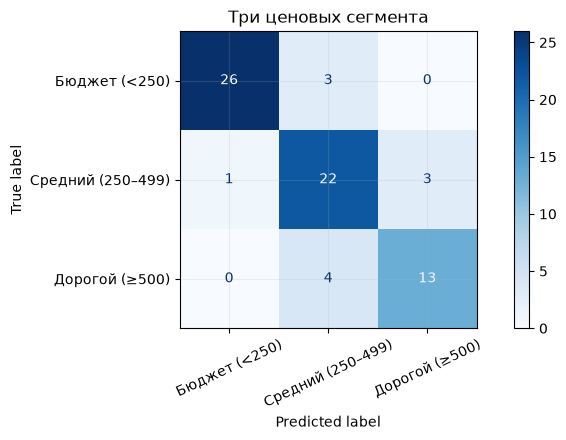

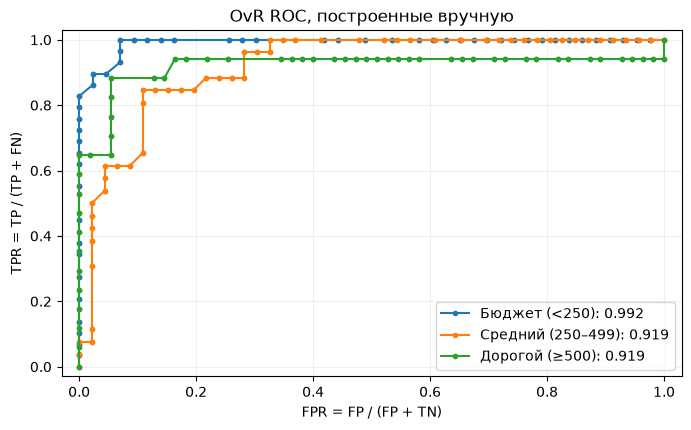

,Сегмент,Количество в test,OvR AUC
0,Бюджет (<250),29,0.9920
1,Средний (250–499),26,0.9193
2,Дорогой (≥500),17,0.9193


,macro,weighted,micro,samples
Три сегмента,0.9435,0.9486,0.9537,0.9167


,threshold,TP,FP,FN,TN,accuracy,recall,precision
39,0.250000,15,7,2,48,0.875000,0.882353,0.681818
46,0.469555,14,3,3,52,0.916667,0.823529,0.823529
55,0.750000,11,1,6,54,0.902778,0.647059,0.916667


t=0.250000: accuracy=(15+48)/72=0.8750; recall=15/(15+2)=0.8824; precision=15/(15+7)=0.6818
t=0.469555: accuracy=(14+52)/72=0.9167; recall=14/(14+3)=0.8235; precision=14/(14+3)=0.8235
t=0.750000: accuracy=(11+54)/72=0.9028; recall=11/(11+6)=0.6471; precision=11/(11+1)=0.9167


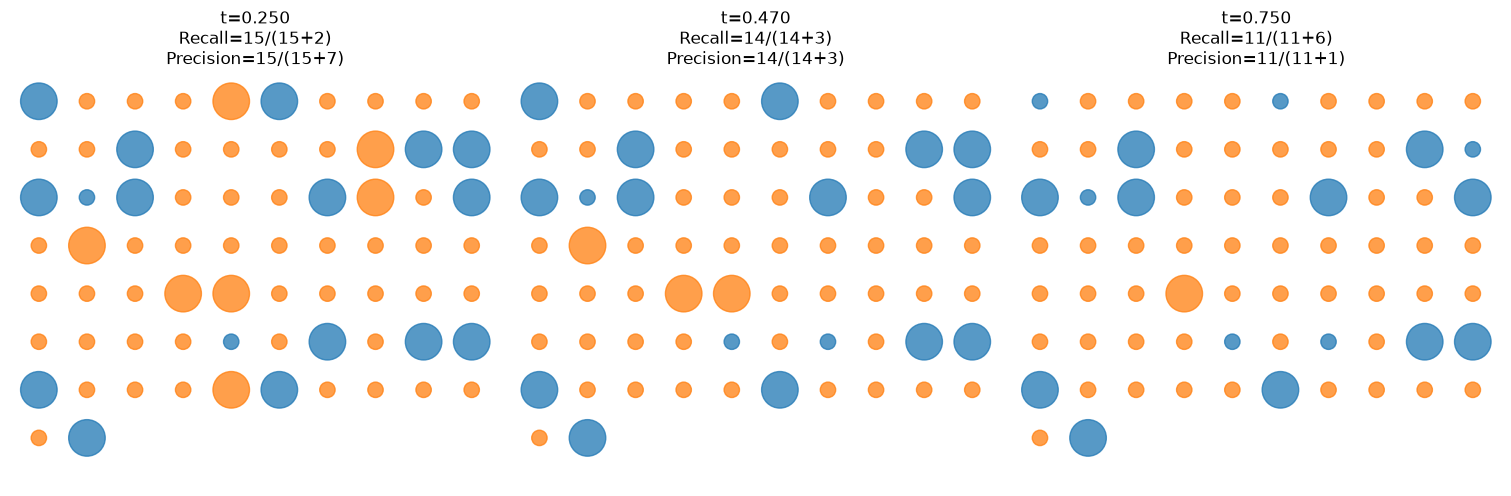

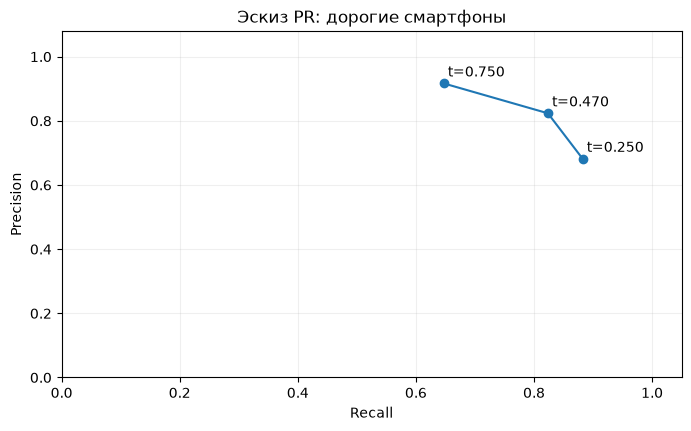

In [6]:
multi_search = GridSearchCV(classifier_pipeline(LogisticRegression(solver='lbfgs', max_iter=2000,
                                        class_weight='balanced', random_state=SEED)),
                            {'model__C':[.01,.1,1,10,100]}, scoring='f1_macro', cv=cv, n_jobs=1)
multi_search.fit(X_train, ym_train, groups=g_train)
multi_model = multi_search.best_estimator_
probs = multi_model.predict_proba(X_test)
pred_multi = multi_model.predict(X_test)
print('Многоклассовый C:',multi_search.best_params_,'CV macro F1:',round(multi_search.best_score_,4))
print(classification_report(ym_test,pred_multi,target_names=class_names,zero_division=0))
ConfusionMatrixDisplay.from_predictions(ym_test,pred_multi,display_labels=class_names,cmap='Blues',xticks_rotation=25)
plt.title('Три ценовых сегмента');plt.tight_layout();plt.show()
Y = np.eye(3,dtype=int)[ym_test.to_numpy()]
assert np.array_equal(multi_model.classes_,np.arange(3))
aucs=[]
fig,ax=plt.subplots()
for k,color in enumerate(['tab:blue','tab:orange','tab:green']):
    table,area=manual_roc(Y[:,k],probs[:,k]);aucs.append(area)
    draw_segments(ax,table,f'{class_names[k]}: {area:.3f}',color)
ax.legend();ax.set_title('OvR ROC, построенные вручную');plt.show()
multi_aucs = {'macro':np.mean(aucs), 'weighted':np.average(aucs,weights=Y.sum(axis=0)),
              'micro':manual_roc(Y.ravel(),probs.ravel())[1],
              'samples':np.mean([pair_auc(a,b)[-1] for a,b in zip(Y,probs)])}
for average,area in multi_aucs.items():
    assert np.isclose(area,roc_auc_score(Y,probs,average=average))
display(pd.DataFrame({'Сегмент':class_names,'Количество в test':Y.sum(axis=0),'OvR AUC':aucs}).round(4))
display(pd.DataFrame([multi_aucs],index=['Три сегмента']).round(4))

# Дополнение: три порога дорогого класса с попарно разными accuracy, recall, precision.
# Выбираем их только для иллюстрации ручных расчётов, не оптимизируем модель на test.
from itertools import combinations
real_truth, real_scores = Y[:,2],probs[:,2]
candidate_thresholds = np.unique(np.r_[np.linspace(.05,.95,19), real_scores])
candidates = threshold_metrics(real_truth,real_scores,candidate_thresholds)
selected = None
best_distance = np.inf
values = candidates[['accuracy','recall','precision']].to_numpy()
for indices in combinations(range(len(candidates)),3):
    # Все метрики должны различаться; избегаем практически нулевых порогов.
    thresholds_here = candidates.threshold.iloc[list(indices)].to_numpy()
    if thresholds_here.min() < .01 or thresholds_here.max() > .99:
        continue
    if all(len(set(values[list(indices),j])) == 3 for j in range(3)):
        distance = np.sum((thresholds_here - [.25,.5,.75])**2)
        if distance < best_distance:
            best_distance = distance
            selected = candidates.iloc[list(indices)]
assert selected is not None, 'Для этих предсказаний подходящие три порога не найдены'
display(selected.round(6))
for r in selected.to_dict('records'):
    print(f"t={r['threshold']:.6f}: accuracy=({r['TP']}+{r['TN']})/{len(real_truth)}={r['accuracy']:.4f}; "
          f"recall={r['TP']}/({r['TP']}+{r['FN']})={r['recall']:.4f}; "
          f"precision={r['TP']}/({r['TP']}+{r['FP']})={r['precision']:.4f}")
fig,axes=plt.subplots(1,3,figsize=(15,5),constrained_layout=True)
for ax,r in zip(axes,selected.to_dict('records')):
    pred=real_scores>=r['threshold']
    for i,(truth,guess) in enumerate(zip(real_truth,pred)):
        col,row=i%10,i//10
        ax.add_patch(Circle((col,-row),.38 if guess else .16,
                           color='tab:blue' if truth else 'tab:orange',alpha=.75))
    ax.set(xlim=(-.6,9.6),ylim=(-np.ceil(len(real_truth)/10),.6),aspect='equal')
    ax.axis('off');ax.set_title(f"t={r['threshold']:.3f}\nRecall={r['TP']}/({r['TP']}+{r['FN']})\n"
                               f"Precision={r['TP']}/({r['TP']}+{r['FP']})")
plt.show()
fig,ax=plt.subplots()
s=selected.sort_values('recall');ax.plot(s.recall,s.precision,'o-')
for r in selected.to_dict('records'):
    ax.annotate(f"t={r['threshold']:.3f}",(r['recall'],r['precision']),xytext=(3,5),textcoords='offset points')
ax.set(xlabel='Recall',ylabel='Precision',xlim=(0,1.05),ylim=(0,1.08),title='Эскиз PR: дорогие смартфоны');plt.show()

### 3.3–3.4. Интерпретация и области применения
В примере лекции samples = 0.875 — самая высокая численная оценка, а weighted = 0.75 — самая низкая. Это разные вопросы к данным: высокая samples говорит о хорошем ранжировании меток внутри объекта, а низкая weighted сильнее учитывает слабее распознаваемый класс 2, у которого три положительные метки. Нет универсально «лучшего» варианта AUC.

При переходе от бинарной задачи к нескольким классам AUC **не обязана падать**: меняются цель и набор пар для сравнения. В ценовой задаче добавляется различение бюджетного и среднего сегментов, которые могут иметь схожие характеристики. OvR объединяет остальные сегменты в неоднородный отрицательный класс. При падении AUC это возможные объяснения, но не математический закон. Сравнивать binary AUC и macro AUC как один и тот же показатель нельзя; ниже приводим фактический результат на одном holdout.

- **Macro** — когда все классы одинаково важны: редкие диагнозы, типы дефектов, категории документов. Для смартфонов выбираем его основным AUC, чтобы бюджетный массовый сегмент не скрывал качество остальных.
- **Weighted** — когда нужна оценка под текущую частоту классов: каталог товаров и типичная нагрузка сервиса. При смене частот меняется итог; качество редкого класса может маскироваться.
- **Micro** — когда важна общая масса решений по меткам: массовая многометочная разметка. Чувствителен к сопоставимости шкал оценок разных классов.
- **Samples** — когда важна релевантность меток внутри объекта: рекомендации, теги, набор диагнозов пациента. Не учитывает межобъектное ранжирование и требует положительных и отрицательных меток в каждой строке.

При сильном дисбалансе дополняем ROC AUC метриками precision, recall, PR/AP и матрицей ошибок: высокий ROC AUC сам по себе не задаёт рабочий порог. Определения усреднения: [документация roc_auc_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).

In [7]:
delta=multi_aucs['macro']-lr_metrics['ROC AUC']
direction='ниже' if delta<0 else 'выше либо равен'
display(Markdown(f"**Результат на смартфонах.** Бинарный LR AUC = {lr_metrics['ROC AUC']:.4f}; "
    f"многоклассовый macro AUC = {multi_aucs['macro']:.4f} ({direction}, Δ={delta:+.4f}). "
    f"Минимальный OvR AUC у сегмента «{class_names[int(np.argmin(aucs))]}» ({min(aucs):.4f}). "
    "Именно его сложнее отделить от остальных по используемым признакам. "
    "Вывод относится к текущему разбиению, без доверительных интервалов и оценки будущих цен."))

**Результат на смартфонах.** Бинарный LR AUC = 0.9342; многоклассовый macro AUC = 0.9435 (выше либо равен, Δ=+0.0093). Минимальный OvR AUC у сегмента «Дорогой (≥500)» (0.9193). Именно его сложнее отделить от остальных по используемым признакам. Вывод относится к текущему разбиению, без доверительных интервалов и оценки будущих цен.

<font color='DarkOrange'>**Задание 4 [баллов: 2]:**</font>

Исследуйте вопрос выбросов/новизны для данных в вашем датасете с использованием OneClassSVM (дайте краткую теоретическую характеристику, используйте готовые решения для получения результатов, сделайте выводы)

Материалы:
1) https://scikit-learn.ru/stable/modules/outlier_detection.html,
2) https://alexanderdyakonov.wordpress.com/, Поиск аномалий

### 4. OneClassSVM: выбросы и новизна
OneClassSVM без меток обучает границу области типичных объектов в пространстве признаков. RBF-ядро позволяет получить нелинейную границу; масштабирование обязательно для сравнимого вклада признаков. `nu` — верхняя граница доли ошибок обучения и нижняя граница доли опорных векторов (с оговорками численной оптимизации), **не точная доля будущих аномалий**. `gamma` задаёт локальность RBF; большие значения могут образовать слишком узкую область нормы. `predict=+1` — внутри границы, `−1` — вне; отрицательная `decision_function` указывает на аномальность.

Различаем поиск **выбросов** в обучающей выборке и **новизны** среди ранее не виденных телефонов. Для интерпретируемости используем только шесть числовых характеристик, без бренда и цены. Анализируем чувствительность к nu и gamma; основной вариант фиксирован заранее: `nu=0.1, gamma='scale'`. Разметки аномалий нет, поэтому accuracy/precision детектора честно оценить нельзя. Источники: [OneClassSVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html), [обнаружение новизны и выбросов](https://scikit-learn.org/stable/modules/outlier_detection.html).

,nu,gamma,train_outliers,train_share,test_novelty,test_share,support_vectors
0,0.05,scale,24,0.0842,3,0.0417,38
1,0.05,0.05,16,0.0561,1,0.0139,21
2,0.05,0.5,41,0.1439,13,0.1806,79
3,0.10,scale,33,0.1158,2,0.0278,43
4,0.10,0.05,27,0.0947,2,0.0278,31
5,0.10,0.5,41,0.1439,15,0.2083,81
6,0.20,scale,53,0.1860,8,0.1111,63
7,0.20,0.05,56,0.1965,8,0.1111,61
8,0.20,0.5,61,0.2140,15,0.2083,85


,Brand,Model,storage_gb,ram_gb,screen_inches,camera_main_mp,camera_count,battery_mah,price_usd,decision_score,novelty
96,Blackberry,KEY2,64.0,6.0,4.50,12.0,2,3500.0,699.0,-1.128,True
83,Sony,Xperia 5 III,128.0,8.0,6.10,12.0,3,4500.0,1299.0,-0.033,True
142,Samsung,Galaxy S21 Ultra 5G,256.0,12.0,6.80,108.0,4,5000.0,1199.0,0.000,False
297,Xiaomi,Mi 10T Pro,256.0,8.0,6.67,108.0,3,5000.0,599.0,0.007,False
295,OnePlus,8 Pro,256.0,12.0,6.78,48.0,4,4510.0,999.0,0.033,False
165,Vivo,V21e 5G,128.0,8.0,6.44,64.0,2,4000.0,329.0,0.065,False
285,OnePlus,9 Pro,256.0,12.0,6.70,48.0,4,4500.0,969.0,0.066,False
73,Vivo,X60 Pro,256.0,12.0,6.56,48.0,3,4200.0,799.0,0.103,False
154,Motorola,Edge 20 Fusion,128.0,6.0,6.70,108.0,3,5000.0,499.0,0.124,False
56,Apple,iPhone 13 Pro Max,256.0,6.0,6.70,12.0,3,4352.0,1299.0,0.164,False


,Типичные,Новизна
storage_gb,128.00,96.0
ram_gb,6.00,7.0
screen_inches,6.54,5.3
camera_main_mp,49.00,12.0
camera_count,3.00,2.5
battery_mah,5000.00,4000.0


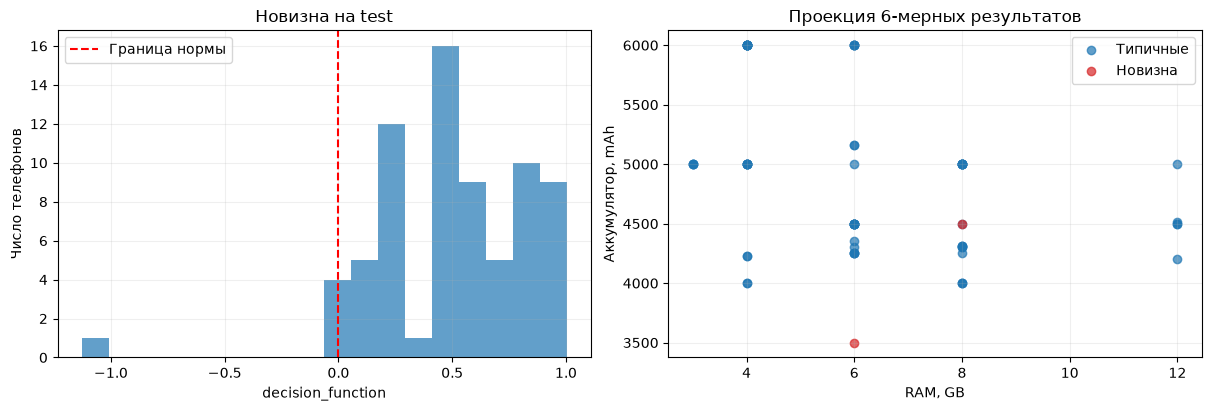

,storage_gb,ram_gb,screen_inches,camera_main_mp,camera_count,battery_mah,score,prediction
Медианные характеристики,128.0,6.0,6.5,48.0,3.0,5000.0,1.157,1
Искусственно экстремальные,128.0,64.0,6.5,48.0,3.0,20000.0,-2.780,-1


**Вывод.** При nu=0.1 и gamma='scale' вне границы: 33/285 объектов train и 2/72 новых объектов test (2.8%). Самый нетипичный в test: Blackberry KEY2. Сравнение медиан показывает, какие характеристики отличаются у отмеченных устройств. Результаты зависят от nu и gamma; редкий дорогой или складной телефон может быть корректным наблюдением. Эти записи требуют проверки источника, автоматическое удаление не обосновано. На графике показана проекция: видимая близость двух точек не означает близость по всем признакам. Обучающая выборка не гарантированно чистая, поэтому трактовка test как новизны условна.

In [8]:
def anomaly_pipeline(nu=.1,gamma='scale'):
    return Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler()),
                     ('model',OneClassSVM(kernel='rbf',nu=nu,gamma=gamma))])
anomaly_rows=[]
for nu in [.05,.1,.2]:
    for gamma in ['scale',.05,.5]:
        model=anomaly_pipeline(nu,gamma).fit(X_train[num_cols])
        anomaly_rows.append({'nu':nu,'gamma':gamma,
            'train_outliers':int((model.predict(X_train[num_cols])==-1).sum()),
            'train_share':float((model.predict(X_train[num_cols])==-1).mean()),
            'test_novelty':int((model.predict(X_test[num_cols])==-1).sum()),
            'test_share':float((model.predict(X_test[num_cols])==-1).mean()),
            'support_vectors':len(model.named_steps['model'].support_)})
display(pd.DataFrame(anomaly_rows).round(4))
ocsvm=anomaly_pipeline().fit(X_train[num_cols])
train_anomalies=(ocsvm.predict(X_train[num_cols])==-1)
test_anomalies=(ocsvm.predict(X_test[num_cols])==-1)
scores=ocsvm.decision_function(X_test[num_cols])
novelty=df.iloc[test_idx].copy()
novelty['decision_score']=scores
novelty['novelty']=test_anomalies
display(novelty.sort_values('decision_score').head(10).round(3))
summary=novelty.groupby('novelty')[num_cols].median().T
summary.columns=['Типичные' if not c else 'Новизна' for c in summary.columns]
display(summary.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].hist(scores,bins=18,color='tab:blue',alpha=.7)
axes[0].axvline(0,color='red',linestyle='--',label='Граница нормы')
axes[0].set(xlabel='decision_function',ylabel='Число телефонов',title='Новизна на test');axes[0].legend()
for mask,label,color in [(~test_anomalies,'Типичные','tab:blue'),(test_anomalies,'Новизна','tab:red')]:
    axes[1].scatter(X_test.loc[mask,'ram_gb'],X_test.loc[mask,'battery_mah'],label=label,color=color,alpha=.7)
axes[1].set(xlabel='RAM, GB',ylabel='Аккумулятор, mAh',title='Проекция 6-мерных результатов');axes[1].legend()
plt.show()
# Синтетическая проверка чувствительности, не доказательство точности детектора.
probe=X_train[num_cols].median().to_frame().T
extreme=probe.copy();extreme['ram_gb']=64;extreme['battery_mah']=20000
probes=pd.concat([probe,extreme],ignore_index=True)
probes.index=['Медианные характеристики','Искусственно экстремальные']
probes['score']=ocsvm.decision_function(probes[num_cols])
probes['prediction']=ocsvm.predict(probes[num_cols])
display(probes.round(3))
display(Markdown(f"**Вывод.** При nu=0.1 и gamma='scale' вне границы: "
    f"{train_anomalies.sum()}/{len(train_anomalies)} объектов train и "
    f"{test_anomalies.sum()}/{len(test_anomalies)} новых объектов test "
    f"({test_anomalies.mean():.1%}). Самый нетипичный в test: "
    f"{novelty.sort_values('decision_score').iloc[0]['Brand']} "
    f"{novelty.sort_values('decision_score').iloc[0]['Model']}. "
    "Сравнение медиан показывает, какие характеристики отличаются у отмеченных устройств. "
    "Результаты зависят от nu и gamma; редкий дорогой или складной телефон может быть корректным "
    "наблюдением. Эти записи требуют проверки источника, автоматическое удаление не обосновано. "
    "На графике показана проекция: видимая близость двух точек не означает близость по всем признакам. "
    "Обучающая выборка не гарантированно чистая, поэтому трактовка test как новизны условна."))